## Import Libraries and Preprocess Raw Data ##

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import matplotlib.colors as mc
import seaborn as sns
from scipy.stats import mannwhitneyu
from statsmodels.stats.multitest import multipletests
import textwrap
import os

## Change path ##

In [3]:
data_path = 'metadata/'
fig_path = './'

In [4]:
protein_groups = pd.read_csv(data_path+'proteingroups_annotated.txt', sep='\t', low_memory=False) #protein groups with genus info annotated
group_info = pd.read_excel(data_path+'group_info.xlsx', sheet_name="PERMANOVA") #dairying grouping info is stored here


protein_groups = protein_groups[protein_groups['Reverse'] != '+']
protein_groups = protein_groups[protein_groups['Only identified by site'] != '+']
protein_groups = protein_groups[protein_groups['Potential contaminant'] != '+']

protein_groups['Unique peptides'] = pd.to_numeric(protein_groups['Unique peptides'], errors='coerce')
protein_groups['Razor + unique peptides'] = pd.to_numeric(protein_groups['Razor + unique peptides'], errors='coerce')
protein_groups['Q-value'] = pd.to_numeric(protein_groups['Q-value'], errors='coerce')

protein_groups_filtered = protein_groups[
    (protein_groups['Unique peptides'] >= 1) &
    (protein_groups['Razor + unique peptides'] >= 2) &
    (protein_groups['Q-value'] <= 0.001)
].copy()

lfq_columns = [col for col in protein_groups_filtered.columns if col.startswith('LFQ intensity')]

# relative abundance of bacterial genera based on summed LFQ intensities
protein_groups_filtered[lfq_columns] = protein_groups_filtered[lfq_columns].div(
    protein_groups_filtered[lfq_columns].sum(axis=0), axis=1
)

protein_groups_filtered = protein_groups_filtered[~(protein_groups_filtered[lfq_columns].eq(0).all(axis=1))].copy()
print("protein groups after filter:", len(protein_groups_filtered))
#protein_groups_filtered.to_excel("protein_groups_filtered.xlsx", index=False)

# genus group in alphabetic order
def normalize_genus_set(value):
    if pd.isna(value):
        return np.nan

    genera = [
        genus.strip()
        for genus in str(value).split(';')
        if genus.strip() and genus.strip().lower() != 'nan'
    ]

    genera = sorted(set(genera), key=str.casefold)
    return ';'.join(genera) if genera else np.nan

protein_groups_filtered['Unique Major Genus'] = (protein_groups_filtered['Unique Major Genus'].apply(normalize_genus_set))
protein_groups_filtered = protein_groups_filtered.dropna(subset=['Unique Major Genus'])

abundance_df = (protein_groups_filtered.groupby('Unique Major Genus')[lfq_columns].sum())

abundance_df = abundance_df.sort_index()

#abundance_df.to_excel(data_path+'genus_abundance.xlsx')

protein groups after filter: 1878


In [4]:
import matplotlib.pyplot as plt

plt.rcParams["pdf.fonttype"] = 42

## Fig 3.a ##

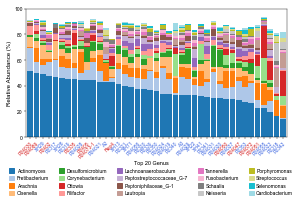

In [ ]:
fig_width = 110
fig_height = 70

plt.rcParams.update({
    "font.family": "Helvetica", "font.size": 5, "axes.linewidth": 0.4,
    "pdf.fonttype": 42, "ps.fonttype": 42, "savefig.bbox": None
})

abundance_df = pd.read_excel(data_path+ 'genus_abundance.xlsx')
abundance_df.columns = ['Genus'] + list(abundance_df.columns[1:])

# keep the 68 distinct genera
filtered_df = abundance_df[~abundance_df['Genus'].str.contains(';', na=False)].copy()
filtered_df.set_index("Genus", inplace=True)

abundance_cols = [col for col in filtered_df.columns if col.startswith('LFQ intensity')]
filtered_df[abundance_cols] = filtered_df[abundance_cols] * 100

top_20_genus = filtered_df[abundance_cols].sum(axis=1).nlargest(20).index
filtered_df = filtered_df.loc[top_20_genus]

if "Actinomyces" in filtered_df.index:
    sorted_samples = filtered_df.loc["Actinomyces"].sort_values(ascending=False).index
    filtered_df = filtered_df[sorted_samples]

filtered_df.columns = [col.replace("LFQ intensity ", "") for col in filtered_df.columns]

cmap = plt.get_cmap('tab20')
unique_colors = [cmap(i) for i in range(len(top_20_genus))]
color_dict = dict(zip(top_20_genus, unique_colors))

ax = filtered_df.T.plot(
    kind="bar", stacked=True, figsize=(fig_width / 25.4, fig_height / 25.4),
    width=0.9, edgecolor="none", legend=False,
    color=[color_dict[genus] for genus in filtered_df.index]
)

ax.set_ylim(0, 100)
ax.set_xlabel("")
ax.set_ylabel("Relative Abundance (%)", fontsize=6, labelpad=2)
ax.tick_params(axis="y", labelsize=5, width=0.4, length=2, pad=1)
ax.tick_params(axis="x", labelsize=5, width=0.4, length=2, pad=1)
plt.setp(ax.get_xticklabels(), rotation=45, ha="right", rotation_mode="anchor")

legend_patches = [mpatches.Patch(color=color_dict[genus], label=genus) for genus in filtered_df.index]
ax.legend(
    handles=legend_patches, bbox_to_anchor=(0.48, -0.15), loc="upper center",
    title="Top 20 Genus", ncol=5, frameon=False, fontsize=5, title_fontsize=5.5,
    handleheight=1, handlelength=1, handletextpad=0.5
)

ax.grid(False)

sample_group_map = dict(zip(group_info["LabNo"], group_info["milk"]))
group_colors = {"no": "tab:red", "yes": "royalblue"}

for xtick, sample in zip(ax.get_xticklabels(), filtered_df.columns):
    xtick.set_color(group_colors.get(sample_group_map.get(sample), "black"))

plt.tight_layout(pad=0.4)
os.makedirs(fig_path, exist_ok=True)
#ax.figure.savefig(os.path.join(fig_path, "top20_genera.pdf"), bbox_inches=None, facecolor="white")
plt.show()

## Extended Fig 4.a ##

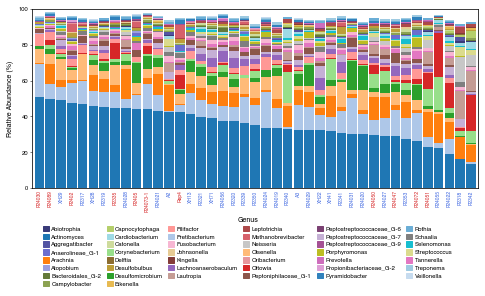

In [5]:
abundance_df = pd.read_excel(data_path + 'genus_abundance.xlsx')
abundance_df.columns = ['Genus'] + list(abundance_df.columns[1:])

filtered_df = abundance_df[~abundance_df['Genus'].str.contains(';', na=False)].copy()
filtered_df.set_index("Genus", inplace=True)

abundance_cols = [col for col in filtered_df.columns if col.startswith('LFQ intensity')]
filtered_df[abundance_cols] = filtered_df[abundance_cols] * 100

filtered_df.columns = [c.replace("LFQ intensity ", "") for c in filtered_df.columns]

top20_genus = filtered_df.sum(axis=1).nlargest(20).index.tolist()

per_sample_top = set()
for sample in filtered_df.columns:
    per_sample_top.update(filtered_df[sample].nlargest(20).index)

new_genus = sorted([g for g in per_sample_top if g not in top20_genus])

final_genus_order = top20_genus + new_genus
if "Actinomyces" in final_genus_order:
    final_genus_order.remove("Actinomyces")
    final_genus_order = ["Actinomyces"] + final_genus_order

filtered_df = filtered_df.loc[final_genus_order]

if "Actinomyces" in filtered_df.index:
    ordered_samples = (
        filtered_df.loc["Actinomyces"]
        .sort_values(ascending=False)
        .index
        .tolist()
    )
else:
    ordered_samples = (
        filtered_df.sum(axis=0)
        .sort_values(ascending=False)
        .index
        .tolist()
    )
filtered_df = filtered_df[ordered_samples]

cmap_main = plt.get_cmap("tab20")  # top20
top20_colors = {g: cmap_main(i) for i, g in enumerate(top20_genus)}

n_new = len(new_genus) # 24 new genus to color
cmap_new_b = plt.get_cmap("tab20b")
cmap_new_c = plt.get_cmap("tab20c")
new_colors_list = [cmap_new_b(i) for i in range(20)] + [cmap_new_c(i) for i in range(20)]

new_genus_colors = {g: new_colors_list[i % len(new_colors_list)] for i, g in enumerate(new_genus)}

color_dict = {**top20_colors, **new_genus_colors}


fig_width = 177
fig_height = 115

plt.rcParams.update({
    "font.family": "Helvetica", "font.size": 6, "pdf.fonttype": 42,
    "ps.fonttype": 42, "axes.linewidth": 0.75
})

ax = filtered_df.T.plot(
    kind='bar',
    stacked=True,
    figsize=(fig_width/25.4,  fig_height/25.4),
    width=0.9,
    edgecolor='none',
    color=[color_dict[g] for g in filtered_df.index]
)

plt.ylim(0, 100)
ax.set_ylabel("Relative Abundance (%)", fontsize=7, labelpad=4)
ax.set_xlabel("")
ax.tick_params(axis='y', labelsize=6, width=0.5, length=2, pad=2)
ax.tick_params(axis='x', labelsize=5, width=0.5, length=0, pad=2)

plt.setp(ax.get_xticklabels(), rotation=90, ha='center', va='top')

for spine in ax.spines.values():
    spine.set_linewidth(0.75)

sorted_legend_genus = sorted(filtered_df.index)
legend_patches = [mpatches.Patch(color=color_dict[g], label=g) for g in sorted_legend_genus]

ax.legend(
    handles=legend_patches,
    bbox_to_anchor=(0.52, 0.35),
    bbox_transform=ax.figure.transFigure,
    loc='upper center',
    ncol=6,
    frameon=False,
    fontsize=6,
    title_fontsize=7,
    title="Genus",
    handleheight=1,
    handlelength=1,
    handletextpad=0.4,
    columnspacing=0.9,
    labelspacing=0.35,
    borderaxespad=0
)

ax.grid(False)
ax.figure.subplots_adjust(left=0.09, right=0.98, bottom=0.43, top=0.98)

sample_group_map = dict(zip(group_info["LabNo"], group_info["milk"]))
group_colors = {'no': 'tab:red', 'yes': 'royalblue'}

x_label_colors = [group_colors.get(sample_group_map.get(lbl, "unknown"), "black") for lbl in filtered_df.columns]

for xtick, color in zip(ax.get_xticklabels(), x_label_colors):
    xtick.set_color(color)

#ax.figure.savefig(os.path.join(fig_path, 'top20_genera_each_sample.pdf'),
    #format='pdf', bbox_inches=None, facecolor='white')
plt.show()

In [ ]:
# save genus color key
color_export_list = []

for genus, color in color_dict.items():
    hex_color = mc.to_hex(color)
    color_export_list.append({'Genus': genus, 'Color': hex_color})

color_export_df = pd.DataFrame(color_export_list)

output_color_file = data_path + "genus_color_mapping.csv"
#color_export_df.to_csv(output_color_file, index=False)

## Fig S6.c ##

Genera needing new color assignment: 14
['Acidovorax', 'Acinetobacter', 'Arsenicicoccus', 'Desulfovibrio', 'Dialister', 'Enterococcus', 'Gemella', 'Haemophilus', 'Jonquetella', 'Mitsuokella', 'Parvimonas', 'Pseudomonas', 'Sanguibacter', 'Staphylococcus']
Available unused colors: 16


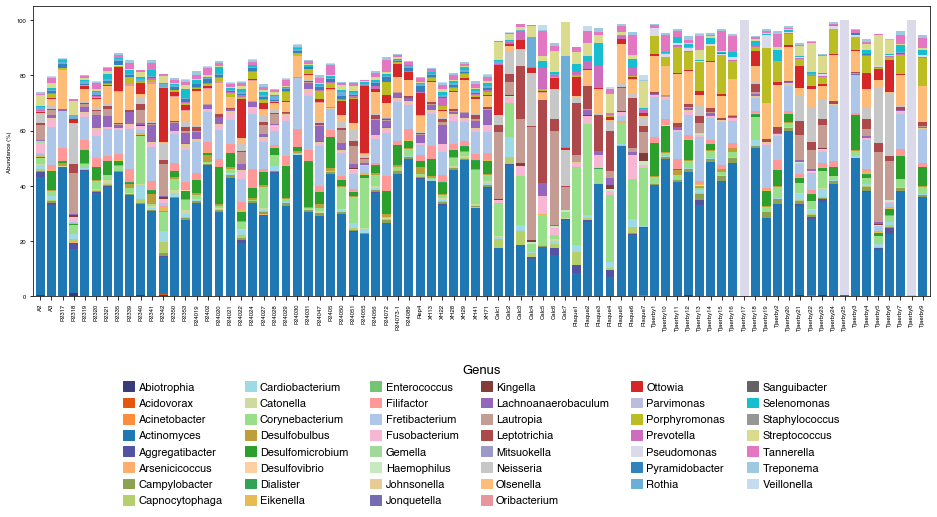

In [6]:
# Data from Jersie-Christensen et al., 2018
nc_data = pd.read_excel(data_path + 'Jersie-Christensen2018_taxonomy_data.xlsx')
abundance_df = pd.read_excel(data_path + 'genus_abundance.xlsx')

abundance_df.columns = ['Genus'] + [col.replace('LFQ intensity ', '') for col in abundance_df.columns[1:]]

nc_data.columns = [col.replace('Abundance ', '') if col.startswith('Abundance') else col for col in nc_data.columns]
nc_data = nc_data[[col for col in nc_data.columns if not col.startswith('Frequency')]]

# normalize nc_data to relative abundance
abundance_cols_nc = [col for col in nc_data.columns if col != 'TaxName']
nc_data_normalized = nc_data.copy()
nc_data_normalized[abundance_cols_nc] = nc_data[abundance_cols_nc].div(nc_data[abundance_cols_nc].sum(), axis=1)

# keep genus present in both dataset
merged_data_nc = pd.merge(
    abundance_df,
    nc_data_normalized[['TaxName'] + abundance_cols_nc],
    left_on='Genus',
    right_on='TaxName',
    how='inner'
).drop(columns=['TaxName'])

abundance_cols_merged = [col for col in merged_data_nc.columns if col != 'Genus']
merged_data_nc[abundance_cols_merged] = merged_data_nc[abundance_cols_merged] * 100


abundance_data = merged_data_nc.set_index('Genus')[abundance_cols_merged]

# color mapping
genus_color_df = pd.read_csv(data_path + "genus_color_mapping.csv")
color_dict = dict(zip(genus_color_df['Genus'], genus_color_df['Color']))

# genera not yet assigned a color
all_genus = abundance_data.index.tolist()
new_genus = [g for g in all_genus if g not in color_dict]

print("Genera needing new color assignment:", len(new_genus))
print(new_genus)

cmap_b = plt.get_cmap('tab20b')
cmap_c = plt.get_cmap('tab20c')

candidate_colors = [mc.to_hex(cmap_b(i)) for i in range(20)] + \
                    [mc.to_hex(cmap_c(i)) for i in range(20)]

used_colors = set(color_dict.values())

available_colors = [c for c in candidate_colors if c not in used_colors]

print("Available unused colors:", len(available_colors))

# assign unused colors to new genera 
if len(available_colors) == 0:
    available_colors = candidate_colors

new_genus_colors = {
    g: available_colors[i % len(available_colors)]
    for i, g in enumerate(new_genus)
}

color_dict_updated = {**color_dict, **new_genus_colors}
colors_plot = [color_dict_updated[g] for g in abundance_data.index]

fig, ax = plt.subplots(figsize=(13, 7.5))

abundance_data.T.plot(
    kind='bar',
    stacked=True,
    width=0.8,
    ax=ax,
    color=colors_plot
)

ax.set_title('')
ax.set_xlabel('')
ax.set_ylabel('Abundance (%)')
plt.xticks(rotation=90)

sorted_legend_genus = sorted(abundance_data.index)
legend_patches = [mpatches.Patch(color=color_dict_updated[g], label=g) for g in sorted_legend_genus]

ax.legend(
    handles=legend_patches,
    bbox_to_anchor=(0.5, -0.2),
    loc='upper center',
    ncol=6,
    frameon=False,
    fontsize=11,
    title_fontsize=13,
    title="Genus",
    handleheight=1,
    handlelength=1,
    handletextpad=0.4
)

ax.grid(False)
plt.tight_layout()

#plt.savefig(os.path.join(fig_path,'genera_compare_nc.pdf'), dpi=300, bbox_inches='tight')
plt.show()

## Fig 3.d ##

     LFQ intensity A2  LFQ intensity A3  LFQ intensity P2317
182          0.000725          0.000589                  0.0
183          0.001475          0.000000                  0.0
196          0.000000          0.000296                  0.0


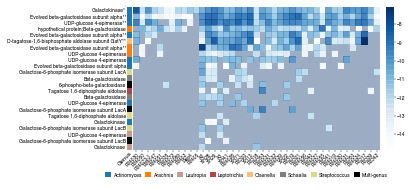

In [7]:
protein_groups = pd.read_excel(data_path+'protein_groups_filtered.xlsx')
# relative abundance before log2 transformation

meta_path = data_path+'metabolism_proteins.xlsx'
output_csv = data_path + 'lactose_protein.csv'

id_col = 'id'  

lactose_df = pd.read_excel(meta_path, sheet_name='lactose')
group_info = pd.read_excel(data_path + 'group_info.xlsx', sheet_name='PERMANOVA')
color_df = pd.read_csv(data_path + 'genus_color_mapping.csv')

lfq_columns = [col for col in protein_groups.columns if col.startswith('LFQ intensity')]

lactose_products = lactose_df['product by PROKKA annotation'].tolist()

def find_matching_products(row, products):
    matches = [p for p in products if p in row]
    return ';'.join(matches) if matches else None

protein_groups['Matching lactose products'] = protein_groups['Unique Major Protein Names'].apply(
    lambda x: find_matching_products(str(x), lactose_products)
)
protein_groups = protein_groups[protein_groups['Matching lactose products'].notna()].copy()


MP = group_info.loc[group_info['milk'] == 'yes', 'LabNo'].tolist()
MN  = group_info.loc[group_info['milk'] == 'no',  'LabNo'].tolist()

cols_MP = [f'LFQ intensity {s}' for s in MP if f'LFQ intensity {s}' in lfq_columns]
cols_MN  = [f'LFQ intensity {s}' for s in MN  if f'LFQ intensity {s}' in lfq_columns]

# data check
print(protein_groups[lfq_columns].iloc[0:3, 0:3])


# Mann-Whitney U tests on relative abundance before log transformation
def calc_u_test(row):
    vals_yes = row[cols_MP].dropna().astype(float)
    vals_no  = row[cols_MN].dropna().astype(float)
    if len(vals_yes) > 0 and len(vals_no) > 0:
        if len(set(vals_yes) | set(vals_no)) == 1:
            return np.nan
        _, p = mannwhitneyu(vals_yes, vals_no, alternative='two-sided', method='asymptotic')
        return p
    return np.nan

protein_groups['P_value_Raw_Data_U_test'] = protein_groups.apply(calc_u_test, axis=1)

# FDR correction
mask_valid = protein_groups['P_value_Raw_Data_U_test'].notna()
qvals = np.full(len(protein_groups), np.nan)
qvals[mask_valid.values] = multipletests(
    protein_groups.loc[mask_valid, 'P_value_Raw_Data_U_test'], method='fdr_bh'
)[1]
protein_groups['Q_value_BH_adj'] = qvals

# 0 -> NaN and then log2 transform for heatmap
protein_groups[lfq_columns] = protein_groups[lfq_columns].replace(0, np.nan)
protein_groups[lfq_columns] = np.log2(protein_groups[lfq_columns])


protein_groups['Modified Protein Names'] = protein_groups['Unique Major Protein Names']
protein_groups.loc[protein_groups['Q_value_BH_adj'] < 0.05, 'Modified Protein Names'] += '*'
protein_groups.loc[protein_groups['Q_value_BH_adj'] < 0.01, 'Modified Protein Names'] += '*'


# protein_groups.to_csv(output_csv, index=False, encoding='utf-8')

protein_major = protein_groups

genus_to_color = dict(zip(color_df.iloc[:, 0], color_df.iloc[:, 1]))

lfq_data = protein_major[lfq_columns].copy()
lfq_data.index = protein_major[id_col]
lfq_data.columns = lfq_data.columns.str.replace(r'^LFQ intensity ', '', regex=True)

missing_data_count = lfq_data.isna().sum()
group_info['NaN_count'] = group_info['LabNo'].map(missing_data_count)

sorted_samples = (
    group_info.sort_values(by=['milk', 'NaN_count'])['LabNo'].tolist()
)
sorted_samples = [s for s in sorted_samples if s in lfq_data.columns]
lfq_data_sorted = lfq_data[sorted_samples].copy()

lfq_data_sorted['NaN_count'] = lfq_data_sorted.isna().sum(axis=1)
lfq_data_sorted = lfq_data_sorted.sort_values(by='NaN_count', ascending=True)
lfq_data_sorted = lfq_data_sorted.drop(columns=['NaN_count'])

genus_dict = protein_major.set_index(id_col)['Unique Major Genus'].to_dict()
ordered_genus = [genus_dict.get(pid, np.nan) for pid in lfq_data_sorted.index]

name_dict = protein_major.set_index(id_col)['Modified Protein Names'].to_dict()
lfq_data_sorted.index = lfq_data_sorted.index.map(name_dict)


genus_colors_mapped = []
for g in ordered_genus:
    if pd.isna(g):
        genus_colors_mapped.append(mc.to_rgba('#E0E0E0'))
    elif ';' in str(g):
        genus_colors_mapped.append(mc.to_rgba('black'))
    else:
        hex_col = genus_to_color.get(g, '#CCCCCC')
        genus_colors_mapped.append(mc.to_rgba(hex_col))



fig_width = 145
fig_height = 70
sample_font, protein_font, legend_font = 5, 5, 5
left_margin = 0.30

plt.rcParams.update({
    "font.family": "Helvetica", "font.size": 5, "axes.labelsize": 6,
    "axes.linewidth": 0.4, "pdf.fonttype": 42, "ps.fonttype": 42,
    "savefig.bbox": None
})

fig = plt.figure(figsize=(fig_width / 25.4, fig_height / 25.4))
gs = fig.add_gridspec(1, 4, width_ratios=[0.5, 25, 0.4, 0.8],
                     left=left_margin, right=0.95, bottom=0.22, top=0.94, wspace=0.02)
ax_genus = fig.add_subplot(gs[0])
ax_main = fig.add_subplot(gs[1])
ax_dummy = fig.add_subplot(gs[2])
ax_dummy.axis("off")
ax_cbar = fig.add_subplot(gs[3])

mask = lfq_data_sorted.isna()
cmap = sns.color_palette("Blues", as_cmap=True)
cmap_with_alpha = cmap(np.linspace(0, 1, 256))
cmap_with_alpha[:, -1] = np.linspace(0, 1, 256)
cmap_with_alpha = mc.ListedColormap(cmap_with_alpha)

sns.heatmap(
    lfq_data_sorted, cmap=cmap_with_alpha, ax=ax_main, cbar_ax=ax_cbar,
    cbar_kws={"label": ""}, annot=False, mask=mask, cbar=True,
    xticklabels=True, yticklabels=False, linewidths=0,
    edgecolors="none", antialiased=False, rasterized=True, zorder=1
)
ax_cbar.tick_params(labelsize=5, length=1.5, width=0.4, pad=1)
ax_cbar.collections[0].set_rasterized(True)
ax_main.set_facecolor("none")

xlim, ylim = ax_main.get_xlim(), ax_main.get_ylim()
ax_main.imshow(mask.to_numpy(), aspect="auto", cmap="Blues", alpha=0.4,
               vmin=0, vmax=1, interpolation="nearest", extent=xlim + ylim, zorder=0)
ax_main.set_xlim(xlim)
ax_main.set_ylim(ylim)
ax_main.set_xlabel("")
ax_main.set_ylabel("")
ax_main.tick_params(axis="x", labelsize=sample_font, length=1.5, width=0.4, pad=1)
plt.setp(ax_main.get_xticklabels(), rotation=45, ha="right", rotation_mode="anchor")

for i, color in enumerate(genus_colors_mapped):
    ax_genus.add_patch(mpatches.Rectangle((0, i), 1, 1, facecolor=color, edgecolor="none", linewidth=0))

ax_genus.set_xlim(0, 1)
ax_genus.set_ylim(len(genus_colors_mapped), 0)
ax_genus.yaxis.tick_left()
ax_genus.set_yticks(np.arange(len(lfq_data_sorted.index)) + 0.5)
protein_labels = [str(x).strip() for x in lfq_data_sorted.index]
ax_genus.set_yticklabels(protein_labels, fontsize=protein_font, ha="right")
ax_genus.tick_params(axis="y", length=0, pad=1)
for spine in ax_genus.spines.values():
    spine.set_visible(False)

ax_genus.set_xticks([0.5])
ax_genus.set_xticklabels(["Genus"], fontsize=6, fontfamily="Helvetica", fontweight="bold")
ax_genus.tick_params(axis="x", length=0, pad=1)
plt.setp(ax_genus.get_xticklabels(), rotation=45, ha="right", rotation_mode="anchor")

legend_patches = []
unique_genus = set(g for g in ordered_genus if pd.notna(g))
for g in unique_genus:
    if ";" not in str(g) and g in genus_to_color:
        legend_patches.append(mpatches.Patch(facecolor=genus_to_color[g], edgecolor="none", label=g))
legend_patches.sort(key=lambda patch: patch.get_label())
if any(";" in str(g) for g in ordered_genus if pd.notna(g)):
    legend_patches.append(mpatches.Patch(facecolor="black", edgecolor="none", label="Multi-genus"))

fig.legend(
    handles=legend_patches, loc="upper center", bbox_to_anchor=(0.6, 0.1),
    ncol=8, frameon=False, fontsize=legend_font, handlelength=1.2,
    handleheight=1.2, handletextpad=0.4, columnspacing=0.7, borderaxespad=0
)

#fig.savefig(os.path.join(fig_path, "lactose.pdf"), dpi=600, bbox_inches=None, facecolor="white")
plt.show()


## Extended Fig 5.e ##

MP: 30
MN: 11
starch proteins: 28


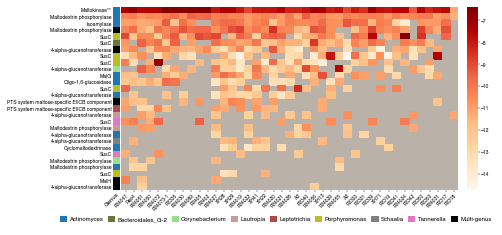

In [8]:
protein_groups = pd.read_excel(data_path+'protein_groups_filtered.xlsx')
# relative abundance before log2 transformation

meta_path = data_path+'metabolism_proteins.xlsx'
output_csv = data_path + 'starch_protein.csv'

id_col = 'id'  

starch_df = pd.read_excel(meta_path, sheet_name='starch')
group_info = pd.read_excel(data_path + 'group_info.xlsx', sheet_name='PERMANOVA')
color_df = pd.read_csv(data_path + 'genus_color_mapping.csv')

lfq_columns = [col for col in protein_groups.columns if col.startswith('LFQ intensity')]
genus_to_color = dict(zip(color_df.iloc[:, 0], color_df.iloc[:, 1]))

starch_products = (
    starch_df['product by PROKKA annotation']
    .dropna()
    .astype(str)
    .tolist()
)

def find_matching_products(row, products):
    matches = [p for p in products if p in str(row)]
    return ';'.join(matches) if matches else None

protein_groups['Matching starch products'] = (protein_groups['Unique Major Protein Names']
                                              .apply(lambda x: find_matching_products(x, starch_products)))

protein_groups = protein_groups[protein_groups['Matching starch products'].notna()].copy()

MP = group_info.loc[group_info['milk'] == 'yes', 'LabNo'].tolist()
MN = group_info.loc[group_info['milk'] == 'no', 'LabNo'].tolist()

cols_MP = [f'LFQ intensity {sample}' for sample in MP if f'LFQ intensity {sample}' in lfq_columns]
cols_MN = [f'LFQ intensity {sample}' for sample in MN if f'LFQ intensity {sample}' in lfq_columns]

print(f'MP: {len(cols_MP)}')
print(f'MN: {len(cols_MN)}')
print(f'starch proteins: {len(protein_groups)}')

# Mann-Whitney U tests on relative abundance before log transformation
def calc_u_test(row):
    vals_yes = row[cols_MP].dropna().astype(float)
    vals_no = row[cols_MN].dropna().astype(float)
    if len(vals_yes) > 0 and len(vals_no) > 0:
        if len(set(vals_yes) | set(vals_no)) == 1:
            return np.nan
        _, p_value = mannwhitneyu(vals_yes, vals_no, alternative='two-sided', method='asymptotic')
        return p_value
    return np.nan

protein_groups['P_value_Raw_Data_U_test'] = protein_groups.apply(calc_u_test, axis=1)

mask_valid = protein_groups['P_value_Raw_Data_U_test'].notna()
qvals = np.full(len(protein_groups), np.nan)
if mask_valid.sum() > 0:
    qvals[mask_valid.values] = multipletests(
        protein_groups.loc[mask_valid, 'P_value_Raw_Data_U_test'], method='fdr_bh'
    )[1]
protein_groups['Q_value_BH_adj'] = qvals

protein_groups['Modified Protein Names'] = protein_groups['Unique Major Protein Names'].astype(str)
protein_groups.loc[protein_groups['Q_value_BH_adj'] < 0.05, 'Modified Protein Names'] += '*'
protein_groups.loc[protein_groups['Q_value_BH_adj'] < 0.01, 'Modified Protein Names'] += '*'

#protein_groups.to_csv(output_csv, index=False, encoding='utf-8-sig')

protein_groups[lfq_columns] = protein_groups[lfq_columns].replace(0, np.nan).astype(float)
protein_groups[lfq_columns] = np.log2(protein_groups[lfq_columns])

lfq_data = protein_groups[lfq_columns].copy()
lfq_data.index = protein_groups[id_col]
lfq_data.columns = lfq_data.columns.str.replace(r'^LFQ intensity ', '', regex=True)

missing_data_count = lfq_data.isna().sum()
group_info = group_info.copy()
group_info['NaN_count'] = group_info['LabNo'].map(missing_data_count)

sorted_samples = group_info.sort_values(by=['milk', 'NaN_count'])['LabNo'].tolist()
sorted_samples = [sample for sample in sorted_samples if sample in lfq_data.columns]
lfq_data_sorted = lfq_data[sorted_samples].copy()

lfq_data_sorted['NaN_count'] = lfq_data_sorted.isna().sum(axis=1)
lfq_data_sorted = lfq_data_sorted.sort_values(by='NaN_count', ascending=True)
lfq_data_sorted = lfq_data_sorted.drop(columns=['NaN_count'])

genus_dict = protein_groups.set_index(id_col)['Unique Major Genus'].to_dict()
ordered_genus = [genus_dict.get(pid, np.nan) for pid in lfq_data_sorted.index]

name_dict = protein_groups.set_index(id_col)['Modified Protein Names'].to_dict()
raw_names = pd.Series(
    [name_dict.get(pid, str(pid)) for pid in lfq_data_sorted.index],
    index=lfq_data_sorted.index
)

#protein name abbreviation
def simplify_protein_names(name):
    key_proteins = ['SusC', 'SusD', 'SusB', 'SusE', 'MalH', 'MalK', 'MalF', 'MalG', 'MalZ', 'MalL', 'MalQ', 'MalP', 'MalX']
    for protein in key_proteins:
        if protein in str(name):
            stars = ''
            if str(name).endswith('**'):
                stars = '**'
            elif str(name).endswith('*'):
                stars = '*'
            return protein + stars
    return str(name)

raw_names_simplified = raw_names.apply(simplify_protein_names)
wrapped_names = raw_names_simplified.apply(lambda x: textwrap.fill(str(x), width=50))
lfq_data_sorted.index = wrapped_names

genus_colors_mapped = []
for genus in ordered_genus:
    if pd.isna(genus):
        genus_colors_mapped.append(mc.to_rgba('#E0E0E0'))
    elif ';' in str(genus):
        genus_colors_mapped.append(mc.to_rgba('black'))
    else:
        hex_color = genus_to_color.get(genus, '#CCCCCC')
        genus_colors_mapped.append(mc.to_rgba(hex_color))

fig_width = 177
fig_height = 85
sample_font, protein_font, legend_font = 5, 5, 6
left_margin = 0.30

plt.rcParams.update({
    "font.family": "Helvetica", "font.size": 5, "axes.labelsize": 6,
    "axes.linewidth": 0.4, "pdf.fonttype": 42, "ps.fonttype": 42,
    "svg.fonttype": "none", "savefig.bbox": None
})

fig = plt.figure(figsize=(fig_width / 25.4, fig_height / 25.4))
gs = fig.add_gridspec(
    1, 4, width_ratios=[0.5, 25, 0.4, 0.8],
    left=left_margin, right=0.95, bottom=0.20, top=0.96, wspace=0.02
)
ax_genus = fig.add_subplot(gs[0])
ax_main = fig.add_subplot(gs[1])
ax_dummy = fig.add_subplot(gs[2])
ax_dummy.axis("off")
ax_cbar = fig.add_subplot(gs[3])

mask = lfq_data_sorted.isna()
sns.heatmap(
    lfq_data_sorted, cmap="OrRd", ax=ax_main, cbar_ax=ax_cbar,
    cbar_kws={"label": ""}, annot=False, mask=mask,
    cbar=True, yticklabels=False, linewidths=0
)
ax_cbar.tick_params(labelsize=5, length=1.5, width=0.4, pad=1)
ax_main.collections[0].colorbar.outline.set_visible(False)
ax_main.set_facecolor("#BAB2A9")
ax_main.set_xlabel("")
ax_main.set_ylabel("")
ax_main.tick_params(
    axis="x", labelsize=sample_font, length=1.5, width=0.4, pad=1
)
plt.setp(
    ax_main.get_xticklabels(),
    rotation=45, ha="right", rotation_mode="anchor"
)

for i, color in enumerate(genus_colors_mapped):
    rect = mpatches.Rectangle(
        (0, i), width=1, height=1,
        facecolor=color, edgecolor="none"
    )
    ax_genus.add_patch(rect)

ax_genus.set_xlim(0, 1)
ax_genus.set_ylim(len(genus_colors_mapped), 0)
ax_genus.yaxis.tick_left()
ax_genus.set_yticks(np.arange(len(lfq_data_sorted.index)) + 0.5)
ax_genus.set_yticklabels(
    lfq_data_sorted.index, fontsize=protein_font, ha="right"
)
ax_genus.tick_params(axis="y", length=0, pad=1)

for spine in ax_genus.spines.values():
    spine.set_visible(False)

ax_genus.set_xticks([0.5])
ax_genus.set_xticklabels(
    ["Genus"], fontsize=6, fontfamily="Helvetica", fontweight="bold"
)
ax_genus.tick_params(axis="x", length=0, pad=1)
plt.setp(
    ax_genus.get_xticklabels(),
    rotation=45, ha="right", rotation_mode="anchor"
)

legend_patches = []
unique_genus = set([g for g in ordered_genus if pd.notna(g)])

for g in unique_genus:
    if ";" not in str(g) and g in genus_to_color:
        legend_patches.append(
            mpatches.Patch(
                facecolor=genus_to_color[g], edgecolor="none", label=g
            )
        )

legend_patches = sorted(legend_patches, key=lambda x: x.get_label())

if any(";" in str(g) for g in ordered_genus if pd.notna(g)):
    legend_patches.append(
        mpatches.Patch(
            facecolor="black", edgecolor="none", label="Multi-genus"
        )
    )

fig.canvas.draw()
renderer = fig.canvas.get_renderer()
label_left = min(
    label.get_window_extent(renderer).x0
    for label in ax_genus.get_yticklabels()
    if label.get_text()
)
padding = fig.dpi * 2 / 25.4
gs.update(left=gs.left + (padding - label_left) / fig.bbox.width)

fig.canvas.draw()
renderer = fig.canvas.get_renderer()
label_bottom = min(
    label.get_window_extent(renderer).y0
    for ax in (ax_main, ax_genus)
    for label in ax.get_xticklabels()
    if label.get_visible() and label.get_text()
)
legend_y = (label_bottom - padding) / fig.bbox.height

fig.legend(
    handles=legend_patches,
    loc="upper center",
    bbox_to_anchor=(0.55, legend_y),
    ncol=9,
    frameon=False,
    fontsize=legend_font,
    handlelength=1.2,
    handleheight=1.2,
    handletextpad=0.4,
    columnspacing=0.7,
    borderaxespad=0
)

#plt.savefig(os.path.join(fig_path,'starch.pdf'), dpi=600)

plt.show()